### Libraries

In [2]:
import pandas as pd
import numpy as np
from wilds import get_dataset

import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

### Dataset

In [3]:
ds = load_dataset("pietrolesci/civilcomments-wilds", "default")

print(ds)
print(ds["train"].column_names)
print(ds["train"][0])

ValueError: Feature type 'List' not found. Available feature types: ['Value', 'ClassLabel', 'Translation', 'TranslationVariableLanguages', 'LargeList', 'Sequence', 'Array2D', 'Array3D', 'Array4D', 'Array5D', 'Audio', 'Image', 'Video', 'Pdf']

In [9]:
print(type(ds))

print("\nAvailable splits:")
print(list(ds.keys()))

print("\nDataset features:")
print(ds["train"].features)

<class 'datasets.dataset_dict.DatasetDict'>

Available splits:
['train', 'test', 'validation']

Dataset features:
{'uid': Value('int64'), 'id': Value('int64'), 'comment_text': Value('string'), 'toxicity': ClassLabel(names=['non-toxic', 'toxic']), 'has_active_attrs': Value('bool'), 'active_attrs': List(Value('string')), 'male': Value('int64'), 'female': Value('int64'), 'LGBTQ': Value('int64'), 'christian': Value('int64'), 'muslim': Value('int64'), 'other_religions': Value('int64'), 'black': Value('int64'), 'white': Value('int64'), 'identity_any': Value('int64'), 'severe_toxicity': Value('int64'), 'obscene': Value('int64'), 'threat': Value('int64'), 'insult': Value('int64'), 'identity_attack': Value('int64'), 'sexual_explicit': Value('int64')}


In [10]:
train_data = ds["train"]
val_data = ds["validation"]
test_data = ds["test"]

print("Train size:", len(train_data))
print("Validation size:", len(val_data))
print("Test size:", len(test_data))

Train size: 267516
Validation size: 45047
Test size: 132730


### Train data

In [11]:
train_metadata_fields = [
    col for col in train_data.column_names
    if col not in ["uid", "id", "comment_text", "toxicity"]
]

print("Available metadata and auxiliary annotation fields:")
print(train_metadata_fields)

print("\nNumber of fields:", len(train_metadata_fields))

Available metadata and auxiliary annotation fields:
['has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']

Number of fields: 17


In [12]:
train_sample = train_data[0]

print(type(train_sample))
print(train_sample)


<class 'dict'>
{'uid': 0, 'id': 668129, 'comment_text': '🤔', 'toxicity': 0, 'has_active_attrs': False, 'active_attrs': [], 'male': 0, 'female': 0, 'LGBTQ': 0, 'christian': 0, 'muslim': 0, 'other_religions': 0, 'black': 0, 'white': 0, 'identity_any': 0, 'severe_toxicity': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_attack': 0, 'sexual_explicit': 0}


In [13]:
for i in range(5):
    print(f"\nTrain Sample {i}")
    print(train_sample)


Train Sample 0
{'uid': 0, 'id': 668129, 'comment_text': '🤔', 'toxicity': 0, 'has_active_attrs': False, 'active_attrs': [], 'male': 0, 'female': 0, 'LGBTQ': 0, 'christian': 0, 'muslim': 0, 'other_religions': 0, 'black': 0, 'white': 0, 'identity_any': 0, 'severe_toxicity': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_attack': 0, 'sexual_explicit': 0}

Train Sample 1
{'uid': 0, 'id': 668129, 'comment_text': '🤔', 'toxicity': 0, 'has_active_attrs': False, 'active_attrs': [], 'male': 0, 'female': 0, 'LGBTQ': 0, 'christian': 0, 'muslim': 0, 'other_religions': 0, 'black': 0, 'white': 0, 'identity_any': 0, 'severe_toxicity': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_attack': 0, 'sexual_explicit': 0}

Train Sample 2
{'uid': 0, 'id': 668129, 'comment_text': '🤔', 'toxicity': 0, 'has_active_attrs': False, 'active_attrs': [], 'male': 0, 'female': 0, 'LGBTQ': 0, 'christian': 0, 'muslim': 0, 'other_religions': 0, 'black': 0, 'white': 0, 'identity_any': 0, 'severe_toxicity': 0, 'obs

In [14]:
print("Comment column type:", type(train_data["comment_text"]))
print("Toxicity column type:", type(train_data["toxicity"]))

print("Number of comments:", len(train_data["comment_text"]))
print("Number of toxicity scores:", len(train_data["toxicity"]))

Comment column type: <class 'datasets.arrow_dataset.Column'>
Toxicity column type: <class 'datasets.arrow_dataset.Column'>
Number of comments: 267516
Number of toxicity scores: 267516


In [15]:
train_df = pd.DataFrame({
    "text": train_data["comment_text"],
    "toxicity": train_data["toxicity"]
})

train_df["label"] = (train_df["toxicity"] >= 0.5).astype(int)

train_df.head()

,text,toxicity,label
0,🤔,0,0
1,"😱 but, what would they do for a bathroom?",0,0
2,😜😂🤣 We are talking about a baker who doesn't a...,0,0
3,😂😂😂😂 is this really the big gossip of barrow ?...,0,0
4,😂😂 you are excited for 2020 for what?? To be l...,0,0


In [16]:
print("Shape:", train_df.shape)

Shape: (267516, 3)


In [17]:
train_df.dtypes

,0
text,object
toxicity,int64
label,int64


In [18]:
train_df.isnull().sum()

,0
text,0
toxicity,0
label,0


In [19]:
train_duplicates = train_df["text"].duplicated().sum()

print("Duplicate comments:", train_duplicates)

Duplicate comments: 0


In [20]:
train_df["label"].value_counts().sort_index()

,count
label,
0,237173
1,30343


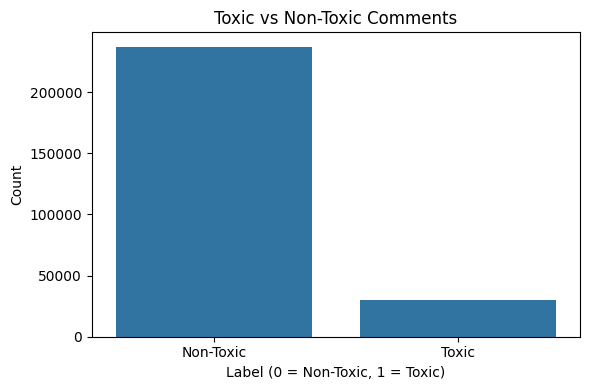

In [21]:
plt.figure(figsize=(6, 4))

sns.countplot(data=train_df, x="label")

plt.title("Toxic vs Non-Toxic Comments")
plt.xlabel("Label (0 = Non-Toxic, 1 = Toxic)")
plt.ylabel("Count")
plt.xticks([0, 1], ["Non-Toxic", "Toxic"])

plt.tight_layout()
plt.show()

In [22]:
label_percentages = train_df["label"].value_counts(normalize=True).sort_index() * 100

label_percentages.index = ["Non-Toxic", "Toxic"]
print(label_percentages)

Non-Toxic    88.657501
Toxic        11.342499
Name: proportion, dtype: float64


In [23]:
train_df["text_length"] = train_df["text"].astype(str).apply(len)

train_df["text_length"].describe()

,text_length
count,267516.000000
mean,353.245649
std,289.852601
min,1.000000
25%,122.000000
50%,258.000000
75%,515.000000
max,1891.000000


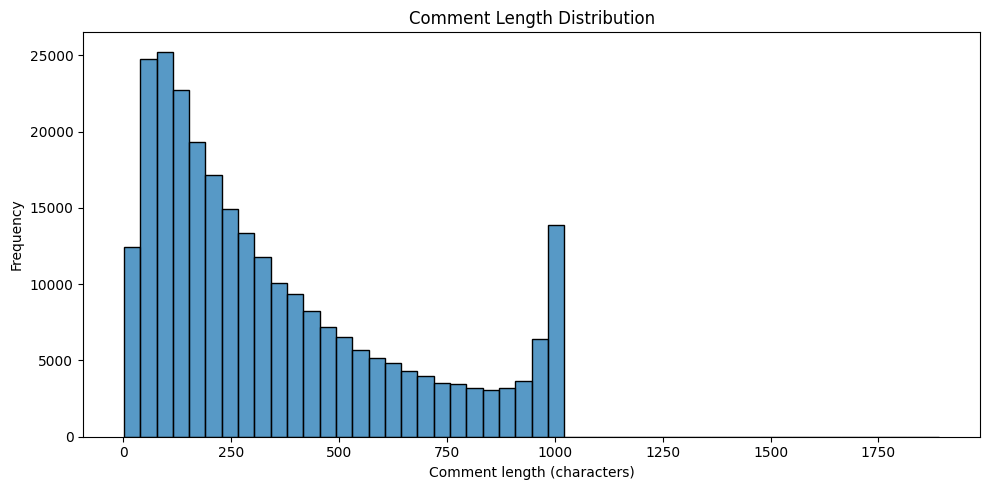

In [24]:
plt.figure(figsize=(10, 5))

sns.histplot(data=train_df, x="text_length", bins=50)

plt.title("Comment Length Distribution")
plt.xlabel("Comment length (characters)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [25]:
print("Metadata and auxiliary annotation fields:")
print(train_metadata_fields)

print("\nExample annotations:")
print(train_sample)

Metadata and auxiliary annotation fields:
['has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']

Example annotations:
{'uid': 0, 'id': 668129, 'comment_text': '🤔', 'toxicity': 0, 'has_active_attrs': False, 'active_attrs': [], 'male': 0, 'female': 0, 'LGBTQ': 0, 'christian': 0, 'muslim': 0, 'other_religions': 0, 'black': 0, 'white': 0, 'identity_any': 0, 'severe_toxicity': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_attack': 0, 'sexual_explicit': 0}


In [26]:

# Convert the complete Hugging Face training split to a DataFrame
train_full_df = ds["train"].to_pandas()

# Select the metadata columns that actually exist
train_metadata_fields = [
    col for col in train_full_df.columns
    if col not in ["uid", "id", "comment_text", "toxicity"]
]

train_meta_df = train_full_df[train_metadata_fields].copy()

print("Metadata shape:", train_meta_df.shape)
print("Metadata columns:")
print(train_meta_df.columns.tolist())

display(train_meta_df.head())


Metadata shape: (267516, 17)
Metadata columns:
['has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']


,has_active_attrs,active_attrs,male,female,LGBTQ,christian,muslim,other_religions,black,white,identity_any,severe_toxicity,obscene,threat,insult,identity_attack,sexual_explicit
0,False,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,False,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,True,[LGBTQ],0,0,1,0,0,0,0,0,1,0,0,0,0,0,0
3,True,[white],0,0,0,0,0,0,0,1,1,0,0,0,0,0,0
4,False,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [27]:
train_meta_df.head()

,has_active_attrs,active_attrs,male,female,LGBTQ,christian,muslim,other_religions,black,white,identity_any,severe_toxicity,obscene,threat,insult,identity_attack,sexual_explicit
0,False,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,False,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,True,[LGBTQ],0,0,1,0,0,0,0,0,1,0,0,0,0,0,0
3,True,[white],0,0,0,0,0,0,0,1,1,0,0,0,0,0,0
4,False,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [28]:
train_meta_df.isnull().sum().sort_values(ascending=False)

,0
has_active_attrs,0
active_attrs,0
male,0
female,0
LGBTQ,0
christian,0
muslim,0
other_religions,0
black,0
white,0


In [29]:
from pathlib import Path

report_dir = Path("reports")
report_dir.mkdir(parents=True, exist_ok=True)

summary_path = report_dir / "EDA_summary.txt"

with open(summary_path, "w", encoding="utf-8") as f:
    f.write("CivilComments EDA Summary\n")
    f.write("=========================\n\n")

    f.write(f"Training DataFrame Shape: {train_df.shape}\n")
    f.write(f"Number of duplicate comments: {train_duplicates}\n")

    f.write("\nLabel Distribution:\n")
    f.write(train_df["label"].value_counts().sort_index().to_string())

    f.write("\n\nLabel Percentages:\n")
    f.write(label_percentages.to_string())

    f.write("\n\nText Length Statistics:\n")
    f.write(train_df["text_length"].describe().to_string())

    f.write("\n\nMetadata Fields:\n")
    f.write("\n".join(train_metadata_fields))

    f.write("\n\nMissing Values in Metadata:\n")
    f.write(train_meta_df.isnull().sum().to_string())

print(f"EDA summary saved to: {summary_path.resolve()}")

EDA summary saved to: /content/drive/MyDrive/ele680/final project/reports/EDA_summary.txt


#### Columns in Training data

In [30]:
for col in train_metadata_fields:
    print(col)

has_active_attrs
active_attrs
male
female
LGBTQ
christian
muslim
other_religions
black
white
identity_any
severe_toxicity
obscene
threat
insult
identity_attack
sexual_explicit


In [31]:
identity_summary = {}

for col in train_metadata_fields:
    try:
        identity_summary[col] = (train_meta_df[col] > 0).sum()
    except:
        pass

train_identity_df = (
    pd.DataFrame.from_dict(
        identity_summary,
        orient="index",
        columns=["count"]
    )
    .sort_values("count", ascending=False)
)

train_identity_df

,count
identity_any,112876
has_active_attrs,107551
female,36082
male,29681
christian,26645
insult,18380
white,16560
muslim,13836
black,9824
LGBTQ,8369


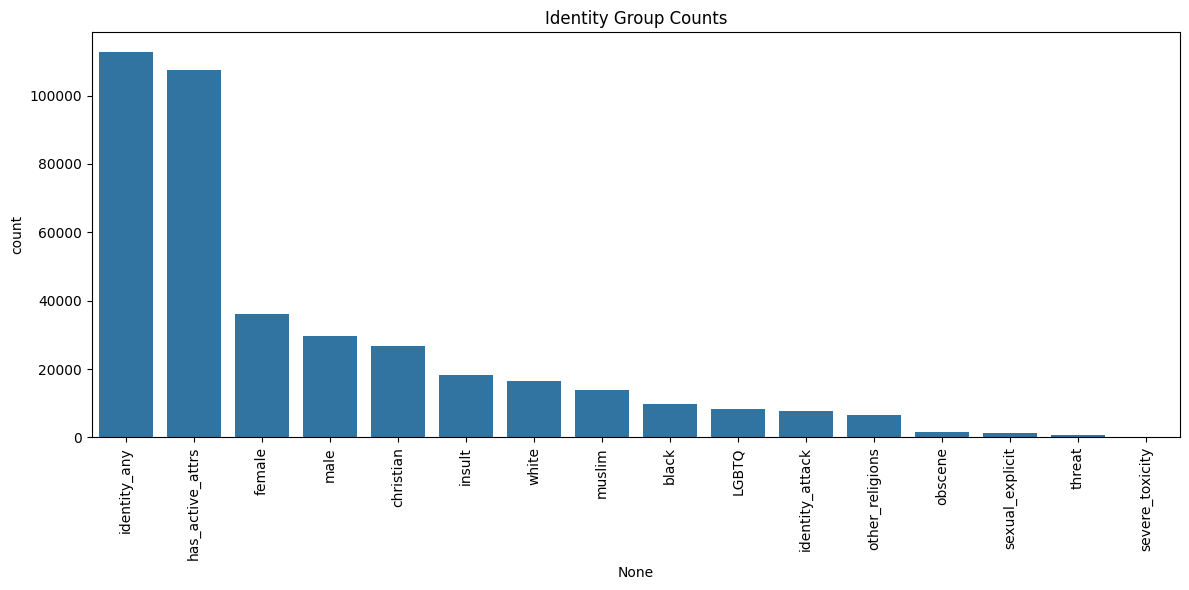

In [32]:
plt.figure(figsize=(12,6))

sns.barplot(
    x=train_identity_df.index,
    y=train_identity_df["count"]
)

plt.xticks(rotation=90)

plt.title("Identity Group Counts")
plt.tight_layout()
plt.show()

In [33]:
train_group_toxicity = []

for col in train_identity_df.index:
    subset = train_meta_df[col] > 0

    if subset.sum() > 0:
        toxicity_rate = train_df.loc[subset, "label"].mean()

        train_group_toxicity.append({
            "group": col,
            "toxicity_rate": toxicity_rate,
            "count": subset.sum()
        })

train_group_toxicity_df = pd.DataFrame(train_group_toxicity)

train_group_toxicity_df.sort_values(
    "toxicity_rate",
    ascending=False
)

,group,toxicity_rate,count
15,severe_toxicity,1.000000,7
12,obscene,0.980930,1678
5,insult,0.980359,18380
14,threat,0.980243,658
10,identity_attack,0.927927,7756
13,sexual_explicit,0.846786,1338
8,black,0.313721,9824
6,white,0.280435,16560
9,LGBTQ,0.269088,8369
7,muslim,0.224270,13836


In [34]:
print(train_metadata_fields)
for col in train_metadata_fields:
    print(col)

['has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']
has_active_attrs
active_attrs
male
female
LGBTQ
christian
muslim
other_religions
black
white
identity_any
severe_toxicity
obscene
threat
insult
identity_attack
sexual_explicit


In [35]:
train_identity_counts = {}

for col in train_metadata_fields:
    try:
        train_identity_counts[col] = (train_meta_df[col] > 0).sum()
    except:
        continue

train_identity_df = pd.DataFrame.from_dict(
    train_identity_counts,
    orient="index",
    columns=["count"]
)

train_identity_df = train_identity_df.sort_values(
    by="count",
    ascending=False
)

train_identity_df.head(20)

,count
identity_any,112876
has_active_attrs,107551
female,36082
male,29681
christian,26645
insult,18380
white,16560
muslim,13836
black,9824
LGBTQ,8369


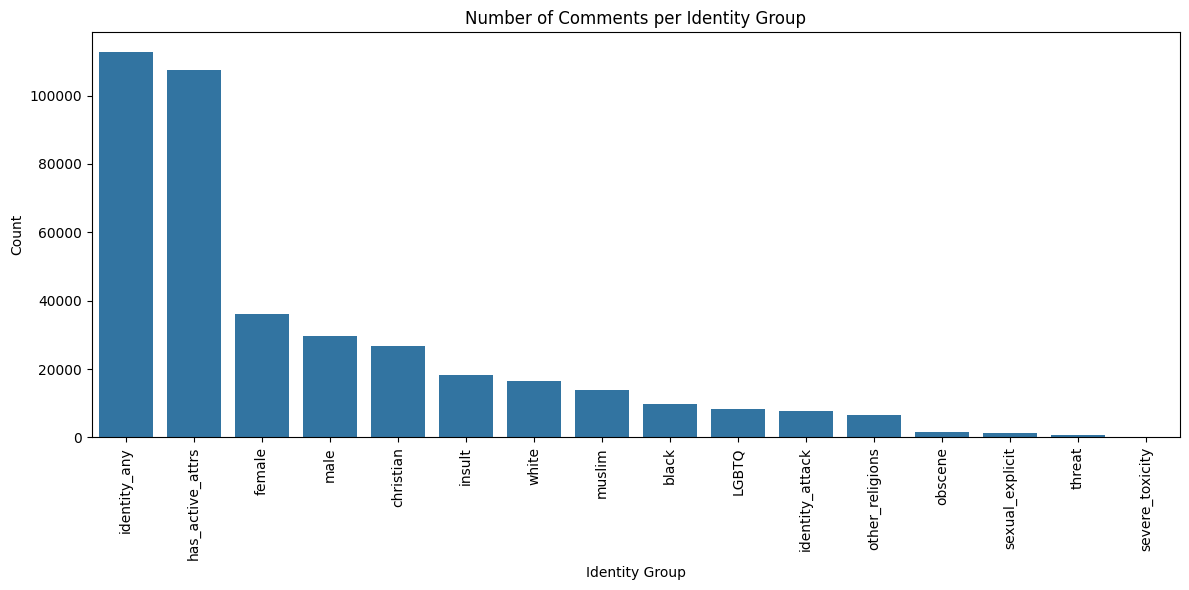

In [36]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=train_identity_df.reset_index(),
    x="index",
    y="count"
)

plt.xticks(rotation=90)
plt.title("Number of Comments per Identity Group")
plt.xlabel("Identity Group")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

In [37]:

# Create a DataFrame containing identity metadata and toxicity labels
train_full_df = ds["train"].to_pandas()

identity_columns = [
    "male", "female", "LGBTQ", "christian", "muslim",
    "other_religions", "black", "white", "identity_any"
]

# Keep only identity columns that exist in the dataset
identity_columns = [
    col for col in identity_columns
    if col in train_full_df.columns
]

train_identity_df = train_full_df[identity_columns].copy()

# Create binary toxicity labels using the 0.5 threshold
train_identity_df["label"] = (
    train_full_df["toxicity"] >= 0.5
).astype(int)

train_group_stats = []

for col in identity_columns:
    subset = train_identity_df[col] > 0

    if subset.sum() == 0:
        continue

    toxicity_rate = train_identity_df.loc[subset, "label"].mean()

    train_group_stats.append({
        "group": col,
        "count": int(subset.sum()),
        "toxicity_rate": toxicity_rate
    })

train_group_stats_df = pd.DataFrame(train_group_stats)

train_group_stats_df.sort_values(
    by="toxicity_rate",
    ascending=False
).reset_index(drop=True)


,group,count,toxicity_rate
0,black,9824,0.313721
1,white,16560,0.280435
2,LGBTQ,8369,0.269088
3,muslim,13836,0.224270
4,identity_any,112876,0.163480
5,other_religions,6502,0.153337
6,male,29681,0.148614
7,female,36082,0.136772
8,christian,26645,0.091349


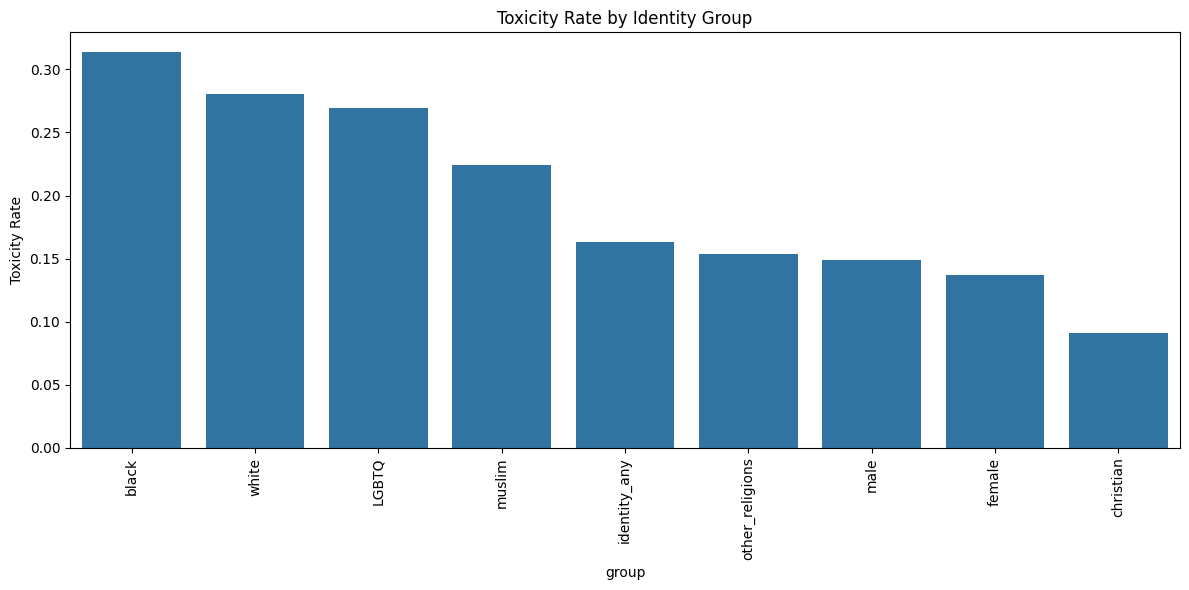

In [38]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=train_group_stats_df.sort_values(
        "toxicity_rate",
        ascending=False
    ),
    x="group",
    y="toxicity_rate"
)

plt.xticks(rotation=90)

plt.title("Toxicity Rate by Identity Group")
plt.ylabel("Toxicity Rate")

plt.tight_layout()
plt.show()

In [39]:
train_group_stats_df.to_csv(
    "reports/group_toxicity_analysis.csv",
    index=False
)

print("Saved successfully")

Saved successfully


### Validation data

In [40]:
val_metadata_fields = [
    col for col in val_data.column_names
    if col not in ["uid", "id", "comment_text", "toxicity"]
]

print("Available metadata and auxiliary annotation fields:")
print(val_metadata_fields)

print("\nNumber of fields:", len(val_metadata_fields))

Available metadata and auxiliary annotation fields:
['has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']

Number of fields: 17


In [41]:
val_sample = val_data[0]

print(type(val_sample))
print(val_sample)

<class 'dict'>
{'uid': 18, 'id': 5711489, 'comment_text': '𝑯𝒆 𝒕𝒐𝒍𝒅 𝒑𝒐𝒍𝒊𝒄𝒆 𝒕𝒉𝒂𝒕 𝒉𝒆 𝒃𝒖𝒚𝒔 𝒄𝒐𝒄𝒂𝒊𝒏𝒆 “𝒊𝒏 𝒍𝒂𝒓𝒈𝒆 𝒒𝒖𝒂𝒏𝒕𝒊𝒕𝒊𝒆𝒔 𝒂𝒏𝒅 𝒖𝒔𝒆𝒔 𝒊𝒕 𝒐𝒗𝒆𝒓 𝒕𝒊𝒎𝒆”\n\nHe\'s been miscast in that musical.  The one he ought to be starring in is the production for children, "The Little Engine That Could".\n\nToot!  Toot!', 'toxicity': 0, 'has_active_attrs': False, 'active_attrs': [], 'male': 0, 'female': 0, 'LGBTQ': 0, 'christian': 0, 'muslim': 0, 'other_religions': 0, 'black': 0, 'white': 0, 'identity_any': 0, 'severe_toxicity': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_attack': 0, 'sexual_explicit': 0}


In [42]:
for i in range(5):
    print(f"\nSample {i}")
    print(val_data[i])


Sample 0
{'uid': 18, 'id': 5711489, 'comment_text': '𝑯𝒆 𝒕𝒐𝒍𝒅 𝒑𝒐𝒍𝒊𝒄𝒆 𝒕𝒉𝒂𝒕 𝒉𝒆 𝒃𝒖𝒚𝒔 𝒄𝒐𝒄𝒂𝒊𝒏𝒆 “𝒊𝒏 𝒍𝒂𝒓𝒈𝒆 𝒒𝒖𝒂𝒏𝒕𝒊𝒕𝒊𝒆𝒔 𝒂𝒏𝒅 𝒖𝒔𝒆𝒔 𝒊𝒕 𝒐𝒗𝒆𝒓 𝒕𝒊𝒎𝒆”\n\nHe\'s been miscast in that musical.  The one he ought to be starring in is the production for children, "The Little Engine That Could".\n\nToot!  Toot!', 'toxicity': 0, 'has_active_attrs': False, 'active_attrs': [], 'male': 0, 'female': 0, 'LGBTQ': 0, 'christian': 0, 'muslim': 0, 'other_religions': 0, 'black': 0, 'white': 0, 'identity_any': 0, 'severe_toxicity': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_attack': 0, 'sexual_explicit': 0}

Sample 1
{'uid': 21, 'id': 5295059, 'comment_text': '为加拿大和中国友谊祝贺。与其想象中国人对加拿大人的看法不如直接去问，不要用自己的想法去猜。本人对传教士没有积极看法，我唯一认识的基督徒曾经想让我相信耶稣可以复活死人，我没有怪他，但当我们聊到一些政治问题的时候，例如中国和美国关系，他和我说美国是不可战胜的，因为圣经说耶稣在美国。他说他把钱全给了教堂，没有结婚，没有孩子。他的想法让我恐惧且战栗，所谓的传教士是这样的话，还是别来了\nCongratulations for the friendship between Canada and China. Instead of imagining the Chinese view of Canadians as to ask directly, do not guess with their own ideas.

In [43]:
print("Comment column type:", type(val_data["comment_text"]))
print("Toxicity column type:", type(val_data["toxicity"]))

print("Number of comments:", len(val_data["comment_text"]))
print("Number of toxicity scores:", len(val_data["toxicity"]))

Comment column type: <class 'datasets.arrow_dataset.Column'>
Toxicity column type: <class 'datasets.arrow_dataset.Column'>
Number of comments: 45047
Number of toxicity scores: 45047


In [44]:
val_df = pd.DataFrame({
    "text": val_data["comment_text"],
    "toxicity": val_data["toxicity"]
})

val_df["label"] = (val_df["toxicity"] >= 0.5).astype(int)

val_df.head()

,text,toxicity,label
0,𝑯𝒆 𝒕𝒐𝒍𝒅 𝒑𝒐𝒍𝒊𝒄𝒆 𝒕𝒉𝒂𝒕 𝒉𝒆 𝒃𝒖𝒚𝒔 𝒄𝒐𝒄𝒂𝒊𝒏𝒆 “𝒊𝒏 𝒍𝒂𝒓𝒈𝒆 ...,0,0
1,为加拿大和中国友谊祝贺。与其想象中国人对加拿大人的看法不如直接去问，不要用自己的想法去猜。本...,0,0
2,♫ Mister we could use a man like Neville Chamb...,0,0
3,…so much for your opinion.,0,0
4,…as most everyone knows both parties completel...,0,0


In [45]:
print("Shape:", val_df.shape)

Shape: (45047, 3)


In [46]:
val_df.dtypes

,0
text,object
toxicity,int64
label,int64


In [47]:
val_df.isnull().sum()

,0
text,0
toxicity,0
label,0


In [48]:
val_duplicates = val_df["text"].duplicated().sum()
print("Duplicate comments in validation set:", val_duplicates)

Duplicate comments in validation set: 0


In [49]:
val_df["label"].value_counts().sort_index()

,count
label,
0,40013
1,5034


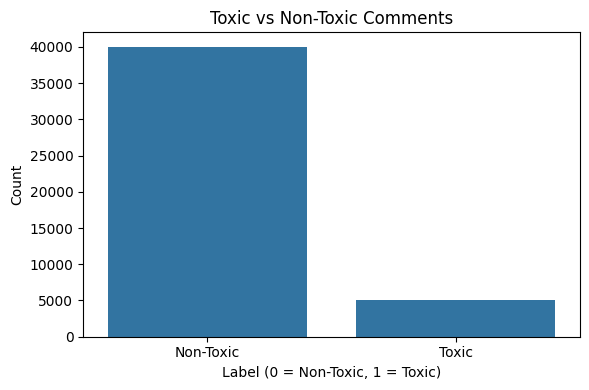

In [50]:
plt.figure(figsize=(6, 4))

sns.countplot(data=val_df, x="label")

plt.title("Toxic vs Non-Toxic Comments")
plt.xlabel("Label (0 = Non-Toxic, 1 = Toxic)")
plt.ylabel("Count")
plt.xticks([0, 1], ["Non-Toxic", "Toxic"])

plt.tight_layout()
plt.show()

In [51]:
val_label_percentages = val_df["label"].value_counts(normalize=True).sort_index() * 100

val_label_percentages.index = ["Non-Toxic", "Toxic"]
print(val_label_percentages)

Non-Toxic    88.825005
Toxic        11.174995
Name: proportion, dtype: float64


In [52]:
val_df["text_length"] = val_df["text"].astype(str).apply(len)

val_df["text_length"].describe()

,text_length
count,45047.000000
mean,353.243390
std,289.672444
min,1.000000
25%,121.000000
50%,259.000000
75%,511.000000
max,1000.000000


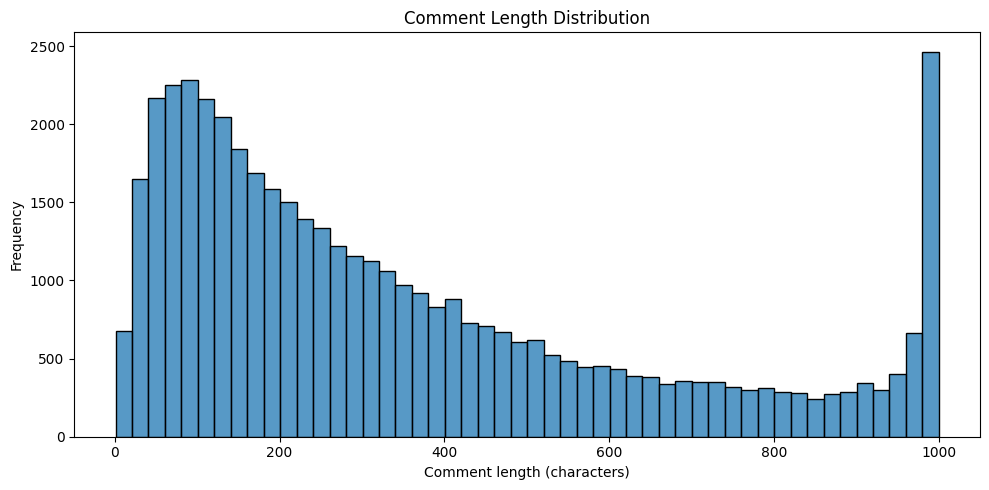

In [53]:
plt.figure(figsize=(10, 5))

sns.histplot(data=val_df, x="text_length", bins=50)

plt.title("Comment Length Distribution")
plt.xlabel("Comment length (characters)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [54]:
print("Metadata and auxiliary annotation fields:")
print(val_metadata_fields)

print("\nExample annotations:")
print(val_sample)

Metadata and auxiliary annotation fields:
['has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']

Example annotations:
{'uid': 18, 'id': 5711489, 'comment_text': '𝑯𝒆 𝒕𝒐𝒍𝒅 𝒑𝒐𝒍𝒊𝒄𝒆 𝒕𝒉𝒂𝒕 𝒉𝒆 𝒃𝒖𝒚𝒔 𝒄𝒐𝒄𝒂𝒊𝒏𝒆 “𝒊𝒏 𝒍𝒂𝒓𝒈𝒆 𝒒𝒖𝒂𝒏𝒕𝒊𝒕𝒊𝒆𝒔 𝒂𝒏𝒅 𝒖𝒔𝒆𝒔 𝒊𝒕 𝒐𝒗𝒆𝒓 𝒕𝒊𝒎𝒆”\n\nHe\'s been miscast in that musical.  The one he ought to be starring in is the production for children, "The Little Engine That Could".\n\nToot!  Toot!', 'toxicity': 0, 'has_active_attrs': False, 'active_attrs': [], 'male': 0, 'female': 0, 'LGBTQ': 0, 'christian': 0, 'muslim': 0, 'other_religions': 0, 'black': 0, 'white': 0, 'identity_any': 0, 'severe_toxicity': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_attack': 0, 'sexual_explicit': 0}


In [55]:

# Convert the full validation split to a DataFrame
val_full_df = ds["validation"].to_pandas()

# Select metadata fields that exist in the validation dataset
val_metadata_fields = [
    col for col in val_full_df.columns
    if col not in ["uid", "id", "comment_text", "toxicity"]
]

val_meta_df = val_full_df[val_metadata_fields].copy()

print("Metadata shape:", val_meta_df.shape)
print("Metadata column count:", len(val_meta_df.columns))

display(val_meta_df.head())


Metadata shape: (45047, 17)
Metadata column count: 17


,has_active_attrs,active_attrs,male,female,LGBTQ,christian,muslim,other_religions,black,white,identity_any,severe_toxicity,obscene,threat,insult,identity_attack,sexual_explicit
0,False,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,True,[christian],0,0,0,1,0,0,0,0,1,0,0,0,0,0,0
2,True,[male],1,0,0,0,0,0,0,0,1,0,0,0,0,0,0
3,False,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,False,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [56]:
val_meta_df.head()

,has_active_attrs,active_attrs,male,female,LGBTQ,christian,muslim,other_religions,black,white,identity_any,severe_toxicity,obscene,threat,insult,identity_attack,sexual_explicit
0,False,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,True,[christian],0,0,0,1,0,0,0,0,1,0,0,0,0,0,0
2,True,[male],1,0,0,0,0,0,0,0,1,0,0,0,0,0,0
3,False,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,False,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [57]:
val_meta_df.isnull().sum().sort_values(ascending=False)

,0
has_active_attrs,0
active_attrs,0
male,0
female,0
LGBTQ,0
christian,0
muslim,0
other_religions,0
black,0
white,0


In [58]:
from pathlib import Path

report_dir = Path("reports")
report_dir.mkdir(parents=True, exist_ok=True)

valsummary_path = report_dir / "validation_EDA_summary.txt"

with open(valsummary_path, "w", encoding="utf-8") as f:
    f.write("CivilComments EDA Summary\n")
    f.write("=========================\n\n")

    f.write(f"Validation DataFrame Shape: {val_df.shape}\n")
    f.write(f"Number of duplicate comments: {val_duplicates}\n")

    f.write("\nLabel Distribution:\n")
    f.write(val_df["label"].value_counts().sort_index().to_string())

    f.write("\n\nLabel Percentages:\n")
    f.write(val_label_percentages.to_string())

    f.write("\n\nText Length Statistics:\n")
    f.write(val_df["text_length"].describe().to_string())

    f.write("\n\nMetadata Fields:\n")
    f.write("\n".join(val_metadata_fields))

    f.write("\n\nMissing Values in Metadata:\n")
    f.write(val_meta_df.isnull().sum().to_string())

print(f"EDA summary saved to: {valsummary_path.resolve()}")

EDA summary saved to: /content/drive/MyDrive/ele680/final project/reports/validation_EDA_summary.txt


#### Columns in Validation data

In [59]:
for col in val_metadata_fields:
    print(col)

has_active_attrs
active_attrs
male
female
LGBTQ
christian
muslim
other_religions
black
white
identity_any
severe_toxicity
obscene
threat
insult
identity_attack
sexual_explicit


In [60]:
val_identity_summary = {}

for col in val_metadata_fields:
    try:
        val_identity_summary[col] = (val_meta_df[col] > 0).sum()
    except:
        pass

val_identity_df = (
    pd.DataFrame.from_dict(
        val_identity_summary,
        orient="index",
        columns=["count"]
    )
    .sort_values("count", ascending=False)
)

val_identity_df

,count
identity_any,18783
has_active_attrs,17847
female,5871
male,4751
christian,4542
insult,3017
white,2853
muslim,2095
black,1644
LGBTQ,1453


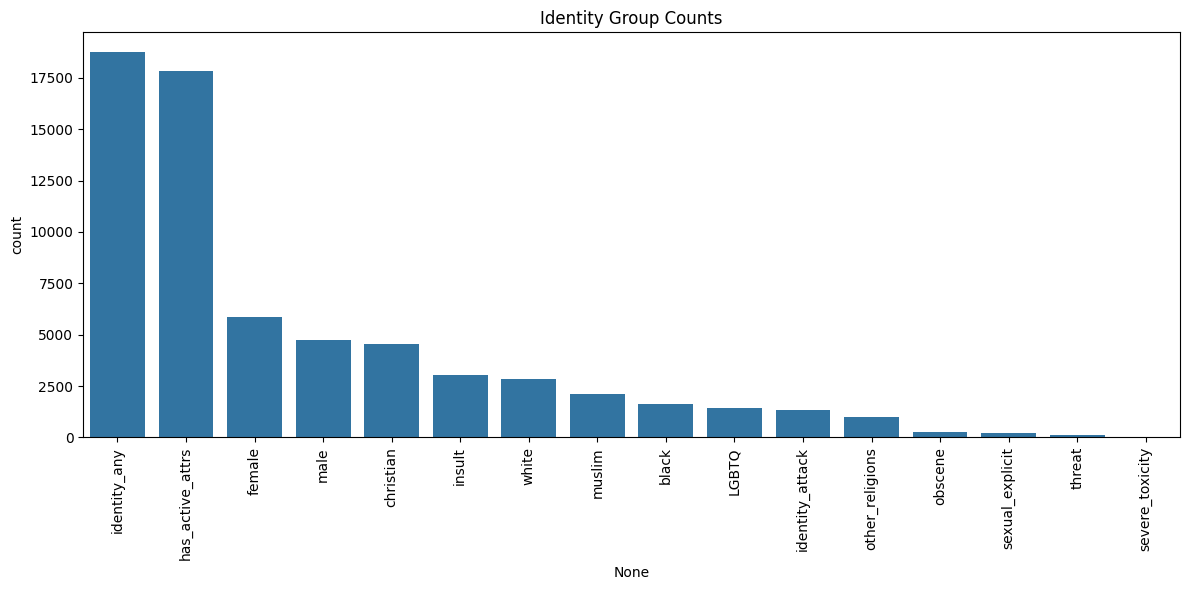

In [61]:
plt.figure(figsize=(12,6))

sns.barplot(
    x=val_identity_df.index,
    y=val_identity_df["count"]
)

plt.xticks(rotation=90)

plt.title("Identity Group Counts")
plt.tight_layout()
plt.show()

In [62]:
val_group_toxicity = []

for col in val_identity_df.index:
    subset = val_meta_df[col] > 0

    if subset.sum() > 0:
        toxicity_rate = val_df.loc[subset, "label"].mean()

        val_group_toxicity.append({
            "group": col,
            "toxicity_rate": toxicity_rate,
            "count": subset.sum()
        })

val_group_toxicity_df = pd.DataFrame(val_group_toxicity)

val_group_toxicity_df.sort_values(
    "toxicity_rate",
    ascending=False
)

,group,toxicity_rate,count
12,obscene,0.996241,266
5,insult,0.983096,3017
14,threat,0.971963,107
10,identity_attack,0.921613,1314
13,sexual_explicit,0.838565,223
8,black,0.322384,1644
6,white,0.295829,2853
9,LGBTQ,0.246387,1453
7,muslim,0.243437,2095
1,has_active_attrs,0.164117,17847


In [63]:
print(val_metadata_fields)
for col in val_metadata_fields:
    print(col)

['has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']
has_active_attrs
active_attrs
male
female
LGBTQ
christian
muslim
other_religions
black
white
identity_any
severe_toxicity
obscene
threat
insult
identity_attack
sexual_explicit


In [64]:
val_identity_counts = {}

for col in val_metadata_fields:
    try:
        val_identity_counts[col] = (val_meta_df[col] > 0).sum()
    except:
        continue

val_identity_df = pd.DataFrame.from_dict(
    val_identity_counts,
    orient="index",
    columns=["count"]
)

val_identity_df = val_identity_df.sort_values(
    by="count",
    ascending=False
)

val_identity_df.head(20)

,count
identity_any,18783
has_active_attrs,17847
female,5871
male,4751
christian,4542
insult,3017
white,2853
muslim,2095
black,1644
LGBTQ,1453


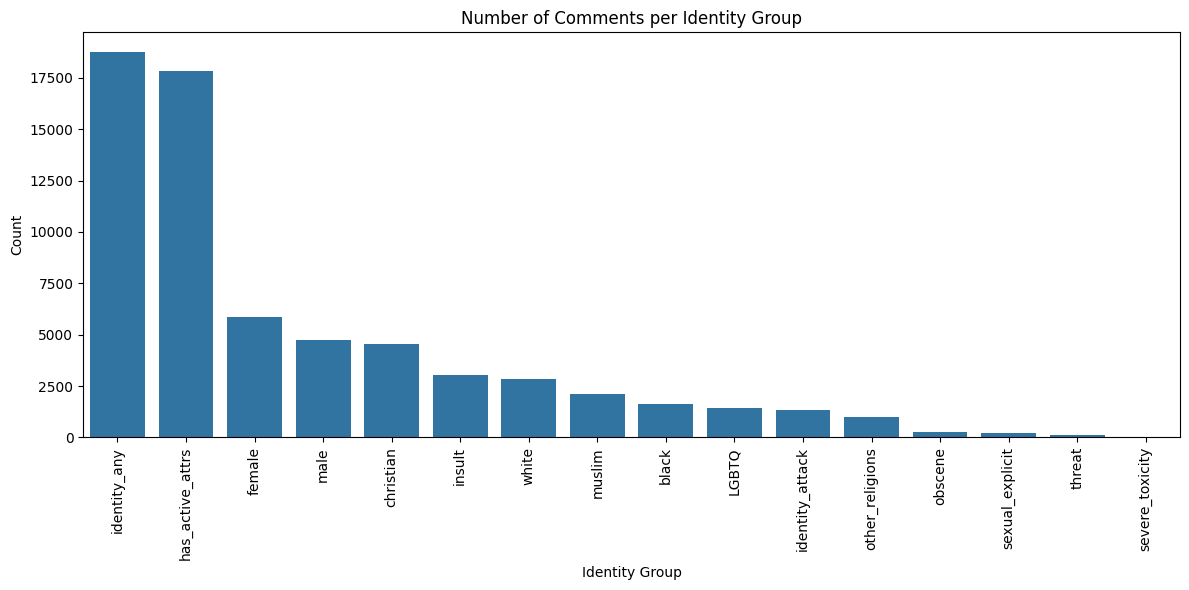

In [65]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=val_identity_df.reset_index(),
    x="index",
    y="count"
)

plt.xticks(rotation=90)
plt.title("Number of Comments per Identity Group")
plt.xlabel("Identity Group")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

In [66]:
val_full_df = ds["validation"].to_pandas()

identity_columns = [
    "male", "female", "LGBTQ", "christian", "muslim",
    "other_religions", "black", "white", "identity_any"
]

identity_columns = [
    col for col in identity_columns
    if col in val_full_df.columns
]

val_identity_df = val_full_df[identity_columns].copy()

# Create binary toxicity labels using the same threshold as the training set
val_identity_df["label"] = (
    val_full_df["toxicity"] >= 0.5
).astype(int)

val_group_stats = []

for col in identity_columns:
    subset = val_identity_df[col] > 0

    if subset.sum() == 0:
        continue

    toxicity_rate = val_identity_df.loc[subset, "label"].mean()

    val_group_stats.append({
        "group": col,
        "count": int(subset.sum()),
        "toxicity_rate": toxicity_rate
    })

val_group_stats_df = pd.DataFrame(val_group_stats)

val_group_stats_df.sort_values(
    by="toxicity_rate",
    ascending=False
).reset_index(drop=True)

,group,count,toxicity_rate
0,black,1644,0.322384
1,white,2853,0.295829
2,LGBTQ,1453,0.246387
3,muslim,2095,0.243437
4,identity_any,18783,0.163605
5,other_religions,983,0.162767
6,male,4751,0.149653
7,female,5871,0.130983
8,christian,4542,0.084544


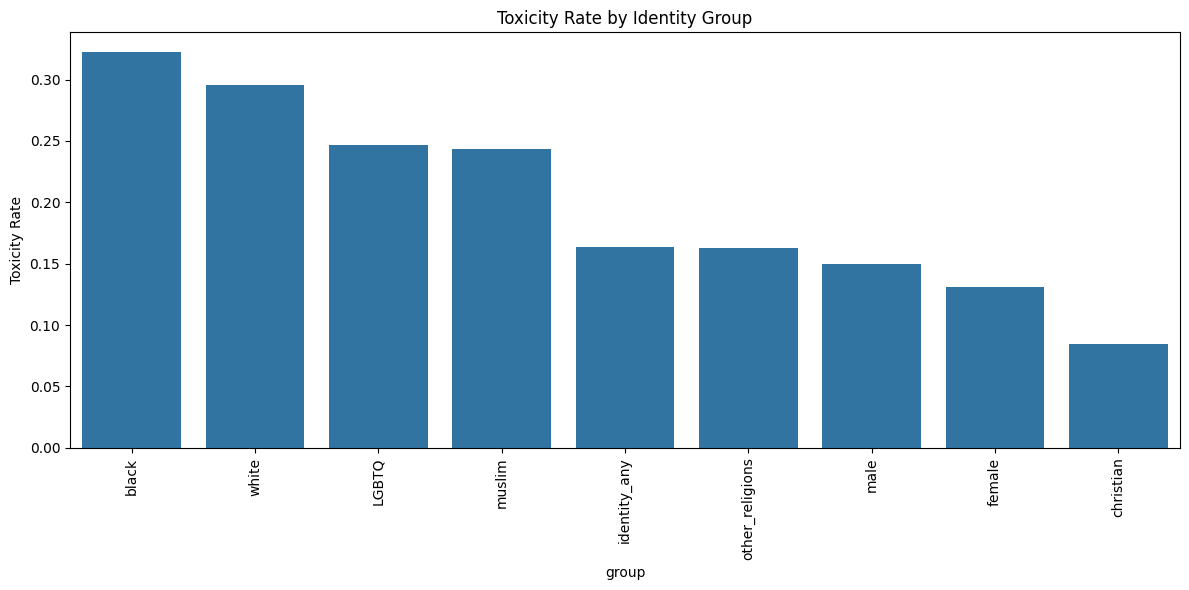

In [67]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=val_group_stats_df.sort_values(
        "toxicity_rate",
        ascending=False
    ),
    x="group",
    y="toxicity_rate"
)

plt.xticks(rotation=90)

plt.title("Toxicity Rate by Identity Group")
plt.ylabel("Toxicity Rate")

plt.tight_layout()
plt.show()

In [68]:
val_group_stats_df.to_csv(
    "reports/val_group_toxicity_analysis.csv",
    index=False
)

print("Saved successfully")

Saved successfully


### Test data

In [69]:
test_metadata_fields = [
    col for col in test_data.column_names
    if col not in ["uid", "id", "comment_text", "toxicity"]
]

print("Available metadata and auxiliary annotation fields:")
print(test_metadata_fields)

print("\nNumber of fields:", len(test_metadata_fields))

Available metadata and auxiliary annotation fields:
['has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']

Number of fields: 17


In [70]:
test_sample = test_data[0]

print(type(test_sample))
print(test_sample)

<class 'dict'>
{'uid': 1, 'id': 7099334, 'comment_text': '😳 mean', 'toxicity': 0, 'has_active_attrs': False, 'active_attrs': [], 'male': 0, 'female': 0, 'LGBTQ': 0, 'christian': 0, 'muslim': 0, 'other_religions': 0, 'black': 0, 'white': 0, 'identity_any': 0, 'severe_toxicity': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_attack': 0, 'sexual_explicit': 0}


In [71]:
for i in range(5):
    print(f"\nTest Sample {i}")
    print(test_sample)


Test Sample 0
{'uid': 1, 'id': 7099334, 'comment_text': '😳 mean', 'toxicity': 0, 'has_active_attrs': False, 'active_attrs': [], 'male': 0, 'female': 0, 'LGBTQ': 0, 'christian': 0, 'muslim': 0, 'other_religions': 0, 'black': 0, 'white': 0, 'identity_any': 0, 'severe_toxicity': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_attack': 0, 'sexual_explicit': 0}

Test Sample 1
{'uid': 1, 'id': 7099334, 'comment_text': '😳 mean', 'toxicity': 0, 'has_active_attrs': False, 'active_attrs': [], 'male': 0, 'female': 0, 'LGBTQ': 0, 'christian': 0, 'muslim': 0, 'other_religions': 0, 'black': 0, 'white': 0, 'identity_any': 0, 'severe_toxicity': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_attack': 0, 'sexual_explicit': 0}

Test Sample 2
{'uid': 1, 'id': 7099334, 'comment_text': '😳 mean', 'toxicity': 0, 'has_active_attrs': False, 'active_attrs': [], 'male': 0, 'female': 0, 'LGBTQ': 0, 'christian': 0, 'muslim': 0, 'other_religions': 0, 'black': 0, 'white': 0, 'identity_any': 0, 'severe_tox

In [72]:
print("Comment column type:", type(test_data["comment_text"]))
print("Toxicity column type:", type(test_data["toxicity"]))

print("Number of comments:", len(test_data["comment_text"]))
print("Number of toxicity scores:", len(test_data["toxicity"]))

Comment column type: <class 'datasets.arrow_dataset.Column'>
Toxicity column type: <class 'datasets.arrow_dataset.Column'>
Number of comments: 132730
Number of toxicity scores: 132730


In [73]:
test_df = pd.DataFrame({
    "text": test_data["comment_text"],
    "toxicity": test_data["toxicity"]
})

test_df["label"] = (test_df["toxicity"] >= 0.5).astype(int)

test_df.head()

,text,toxicity,label
0,😳 mean,0,0
1,😥,0,0
2,😅😅😅😅😅😅😅😅😅😅. Evangelicals call on Trump😂😂😂😂😂😂.,0,0
3,"😂😂😂 she's my lover, man that Suzie Wong 😂😂",0,0
4,💙 ScreenViewsHD 💙 is the best to watch nf...,0,0


In [74]:
print("Shape:", test_df.shape)

Shape: (132730, 3)


In [75]:
test_df.dtypes

,0
text,object
toxicity,int64
label,int64


In [76]:
test_df.isnull().sum()

,0
text,0
toxicity,0
label,0


In [77]:
test_duplicates = test_df["text"].duplicated().sum()
print("Duplicate comments in test set:", test_duplicates)

Duplicate comments in test set: 0


In [78]:
test_df["label"].value_counts().sort_index()

,count
label,
0,117635
1,15095


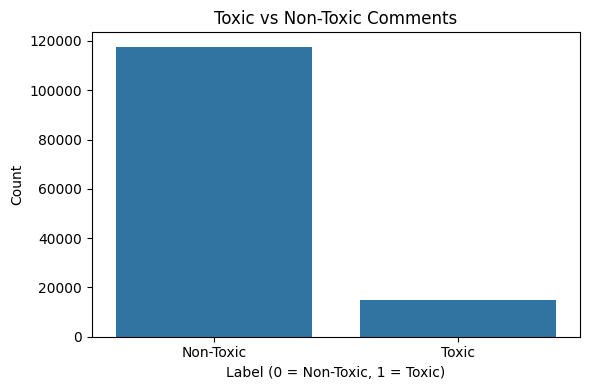

In [79]:
plt.figure(figsize=(6, 4))

sns.countplot(data=test_df, x="label")

plt.title("Toxic vs Non-Toxic Comments")
plt.xlabel("Label (0 = Non-Toxic, 1 = Toxic)")
plt.ylabel("Count")
plt.xticks([0, 1], ["Non-Toxic", "Toxic"])

plt.tight_layout()
plt.show()

In [80]:
test_label_percentages = test_df["label"].value_counts(normalize=True).sort_index() * 100

test_label_percentages.index = ["Non-Toxic", "Toxic"]
print(test_label_percentages)

Non-Toxic    88.627288
Toxic        11.372712
Name: proportion, dtype: float64


In [81]:
test_df["text_length"] = test_df["text"].astype(str).apply(len)

test_df["text_length"].describe()

,text_length
count,132730.000000
mean,350.602094
std,287.602434
min,1.000000
25%,122.000000
50%,256.000000
75%,509.000000
max,1064.000000


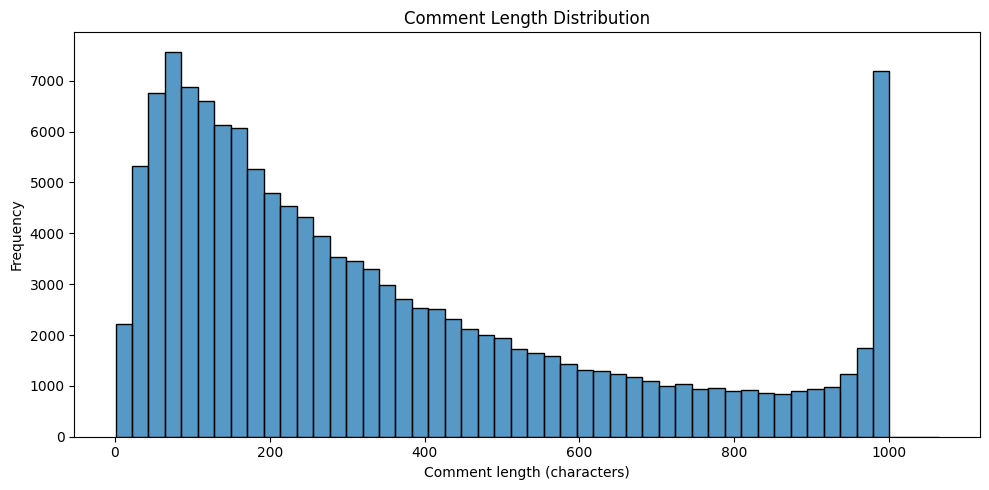

In [82]:
plt.figure(figsize=(10, 5))

sns.histplot(data=test_df, x="text_length", bins=50)

plt.title("Comment Length Distribution")
plt.xlabel("Comment length (characters)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [83]:
print("Metadata and auxiliary annotation fields:")
print(test_metadata_fields)

print("\nExample annotations:")
print(test_sample)

Metadata and auxiliary annotation fields:
['has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']

Example annotations:
{'uid': 1, 'id': 7099334, 'comment_text': '😳 mean', 'toxicity': 0, 'has_active_attrs': False, 'active_attrs': [], 'male': 0, 'female': 0, 'LGBTQ': 0, 'christian': 0, 'muslim': 0, 'other_religions': 0, 'black': 0, 'white': 0, 'identity_any': 0, 'severe_toxicity': 0, 'obscene': 0, 'threat': 0, 'insult': 0, 'identity_attack': 0, 'sexual_explicit': 0}


In [84]:
test_full_df = ds["test"].to_pandas()

test_metadata_fields = [
    col for col in test_full_df.columns
    if col not in ["uid", "id", "comment_text", "toxicity"]
]

test_meta_df = test_full_df[test_metadata_fields].copy()

print("Metadata shape:", test_meta_df.shape)
print("Metadata column count:", len(test_meta_df.columns))

display(test_meta_df.head())

Metadata shape: (132730, 17)
Metadata column count: 17


,has_active_attrs,active_attrs,male,female,LGBTQ,christian,muslim,other_religions,black,white,identity_any,severe_toxicity,obscene,threat,insult,identity_attack,sexual_explicit
0,False,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,False,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,True,[christian],0,0,0,1,0,0,0,0,1,0,0,0,0,0,0
3,True,[male],1,0,0,0,0,0,0,0,1,0,0,0,0,0,0
4,False,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [85]:
test_meta_df.head()

,has_active_attrs,active_attrs,male,female,LGBTQ,christian,muslim,other_religions,black,white,identity_any,severe_toxicity,obscene,threat,insult,identity_attack,sexual_explicit
0,False,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,False,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,True,[christian],0,0,0,1,0,0,0,0,1,0,0,0,0,0,0
3,True,[male],1,0,0,0,0,0,0,0,1,0,0,0,0,0,0
4,False,[],0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [86]:
test_meta_df.isnull().sum().sort_values(ascending=False)

,0
has_active_attrs,0
active_attrs,0
male,0
female,0
LGBTQ,0
christian,0
muslim,0
other_religions,0
black,0
white,0


In [87]:
from pathlib import Path

report_dir = Path("reports")
report_dir.mkdir(parents=True, exist_ok=True)

testsummary_path = report_dir / "Test_EDA_summary.txt"

with open(testsummary_path, "w", encoding="utf-8") as f:
    f.write("CivilComments EDA Summary\n")
    f.write("=========================\n\n")

    f.write(f"Test DataFrame Shape: {test_df.shape}\n")
    f.write(f"Number of duplicate comments: {test_duplicates}\n")

    f.write("\nLabel Distribution:\n")
    f.write(test_df["label"].value_counts().sort_index().to_string())

    f.write("\n\nLabel Percentages:\n")
    f.write(test_label_percentages.to_string())

    f.write("\n\nText Length Statistics:\n")
    f.write(test_df["text_length"].describe().to_string())

    f.write("\n\nMetadata Fields:\n")
    f.write("\n".join(test_metadata_fields))

    f.write("\n\nMissing Values in Metadata:\n")
    f.write(test_meta_df.isnull().sum().to_string())

print(f"EDA summary saved to: {testsummary_path.resolve()}")

EDA summary saved to: /content/drive/MyDrive/ele680/final project/reports/Test_EDA_summary.txt


#### Columns in Test data

In [88]:
for col in test_metadata_fields:
    print(col)

has_active_attrs
active_attrs
male
female
LGBTQ
christian
muslim
other_religions
black
white
identity_any
severe_toxicity
obscene
threat
insult
identity_attack
sexual_explicit


In [89]:
test_identity_summary = {}

for col in test_metadata_fields:
    try:
        test_identity_summary[col] = (test_meta_df[col] > 0).sum()
    except:
        pass

test_identity_df = (
    pd.DataFrame.from_dict(
        test_identity_summary,
        orient="index",
        columns=["count"]
    )
    .sort_values("count", ascending=False)
)

test_identity_df

,count
identity_any,54942
has_active_attrs,52161
female,16335
male,14206
christian,13304
insult,9195
white,7852
muslim,6899
black,4834
LGBTQ,4398


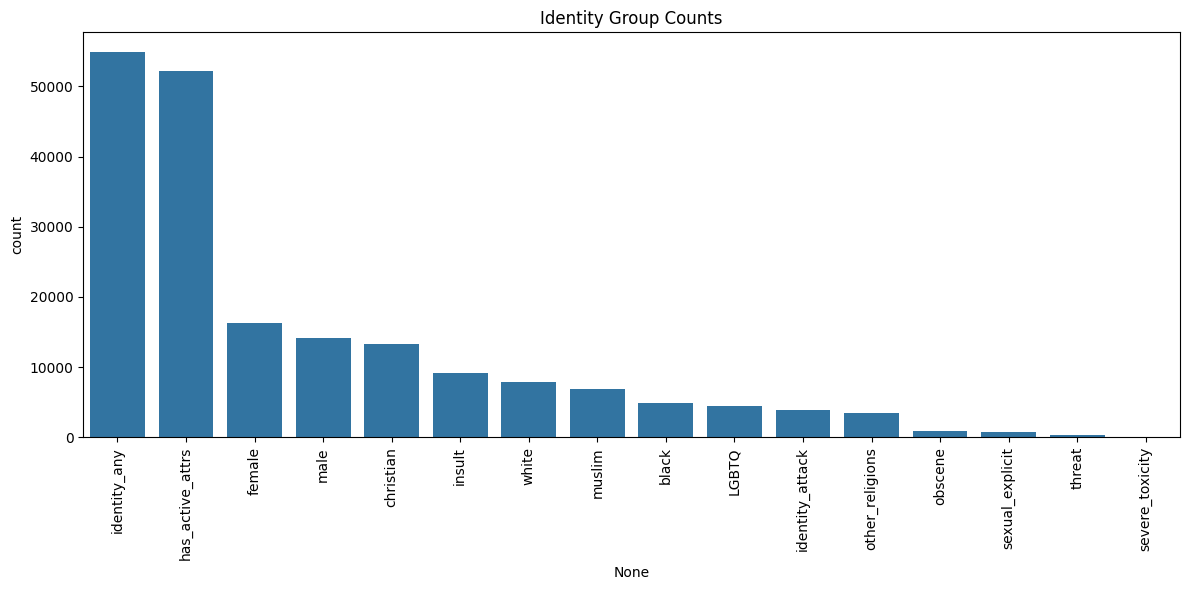

In [90]:
plt.figure(figsize=(12,6))

sns.barplot(
    x=test_identity_df.index,
    y=test_identity_df["count"]
)

plt.xticks(rotation=90)

plt.title("Identity Group Counts")
plt.tight_layout()
plt.show()

In [91]:
test_group_toxicity = []

for col in test_identity_df.index:
    subset = test_meta_df[col] > 0

    if subset.sum() > 0:
        toxicity_rate = test_df.loc[subset, "label"].mean()

        test_group_toxicity.append({
            "group": col,
            "toxicity_rate": toxicity_rate,
            "count": subset.sum()
        })

test_group_toxicity_df = pd.DataFrame(test_group_toxicity)

test_group_toxicity_df.sort_values(
    "toxicity_rate",
    ascending=False
)

,group,toxicity_rate,count
15,severe_toxicity,1.000000,1
5,insult,0.981947,9195
12,obscene,0.980884,837
14,threat,0.968750,320
10,identity_attack,0.917833,3858
13,sexual_explicit,0.876081,694
8,black,0.313819,4834
6,white,0.281202,7852
9,LGBTQ,0.273988,4398
7,muslim,0.234237,6899


In [92]:
print(test_metadata_fields)
for col in test_metadata_fields:
    print(col)

['has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']
has_active_attrs
active_attrs
male
female
LGBTQ
christian
muslim
other_religions
black
white
identity_any
severe_toxicity
obscene
threat
insult
identity_attack
sexual_explicit


In [93]:
test_identity_counts = {}

for col in test_metadata_fields:
    try:
        test_identity_counts[col] = (test_meta_df[col] > 0).sum()
    except:
        continue

test_identity_df = pd.DataFrame.from_dict(
    test_identity_counts,
    orient="index",
    columns=["count"]
)

test_identity_df = test_identity_df.sort_values(
    by="count",
    ascending=False
)

test_identity_df.head(20)

,count
identity_any,54942
has_active_attrs,52161
female,16335
male,14206
christian,13304
insult,9195
white,7852
muslim,6899
black,4834
LGBTQ,4398


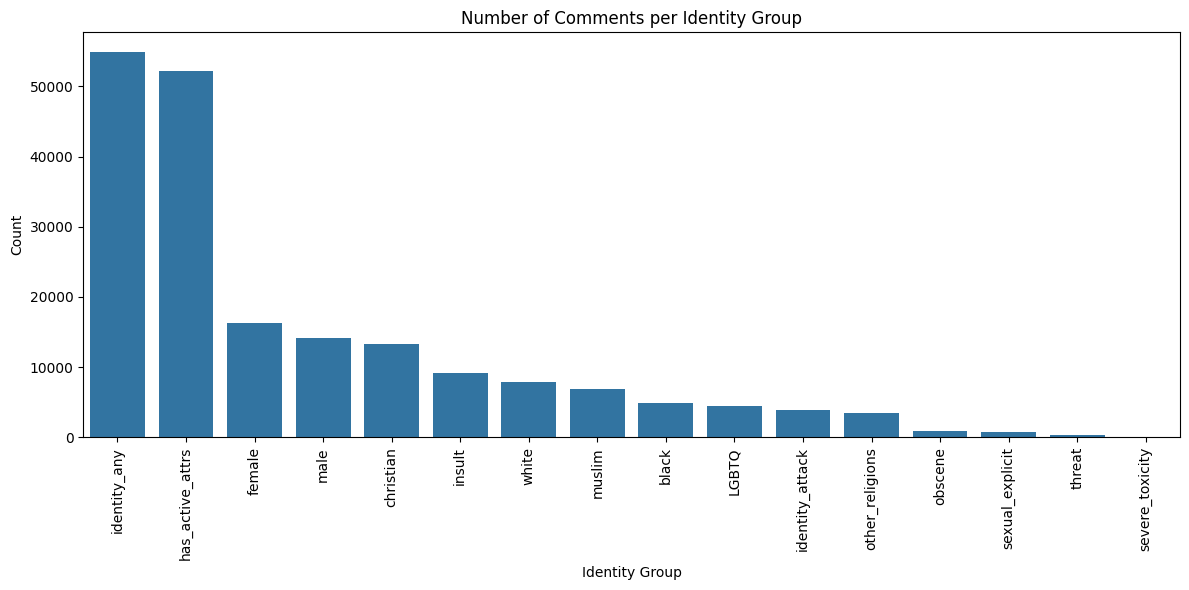

In [94]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=test_identity_df.reset_index(),
    x="index",
    y="count"
)

plt.xticks(rotation=90)
plt.title("Number of Comments per Identity Group")
plt.xlabel("Identity Group")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

In [95]:
test_full_df = ds["test"].to_pandas()

identity_columns = [
    "male", "female", "LGBTQ", "christian", "muslim",
    "other_religions", "black", "white", "identity_any"
]

identity_columns = [
    col for col in identity_columns
    if col in test_full_df.columns
]

test_identity_df = test_full_df[identity_columns].copy()

# Create binary toxicity labels using the same threshold as train and validation
test_identity_df["label"] = (
    test_full_df["toxicity"] >= 0.5
).astype(int)

test_group_stats = []

for col in identity_columns:
    subset = test_identity_df[col] > 0

    if subset.sum() == 0:
        continue

    toxicity_rate = test_identity_df.loc[subset, "label"].mean()

    test_group_stats.append({
        "group": col,
        "count": int(subset.sum()),
        "toxicity_rate": toxicity_rate
    })

test_group_stats_df = pd.DataFrame(test_group_stats)

test_group_stats_df.sort_values(
    by="toxicity_rate",
    ascending=False
).reset_index(drop=True)

,group,count,toxicity_rate
0,black,4834,0.313819
1,white,7852,0.281202
2,LGBTQ,4398,0.273988
3,muslim,6899,0.234237
4,identity_any,54942,0.165192
5,male,14206,0.153949
6,other_religions,3464,0.149249
7,female,16335,0.137863
8,christian,13304,0.094257


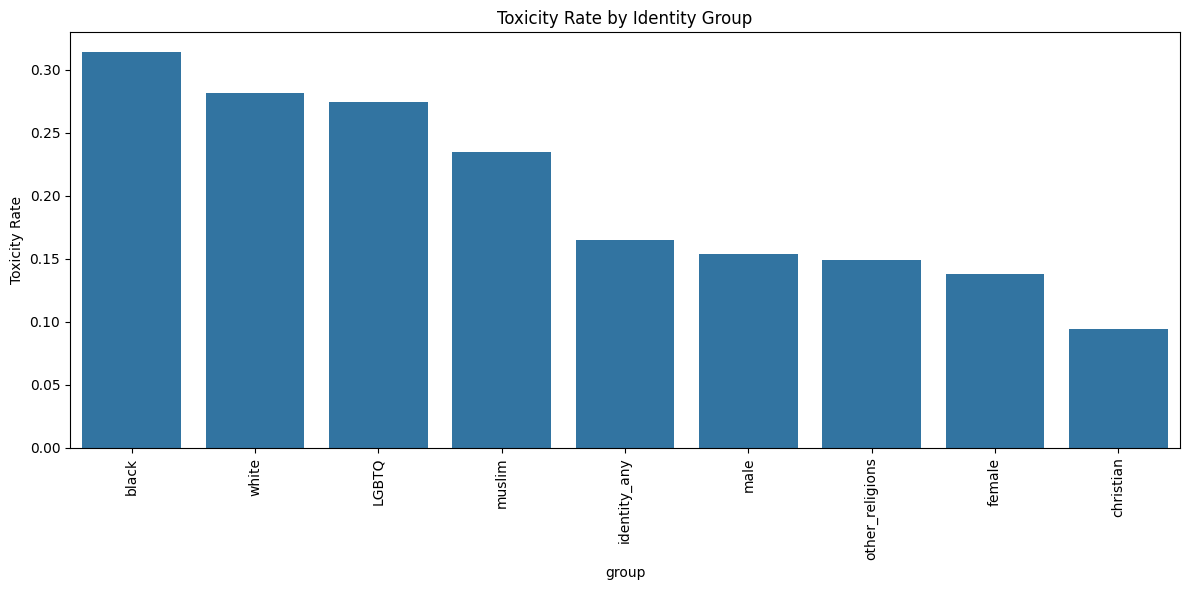

In [96]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=test_group_stats_df.sort_values(
        "toxicity_rate",
        ascending=False
    ),
    x="group",
    y="toxicity_rate"
)

plt.xticks(rotation=90)

plt.title("Toxicity Rate by Identity Group")
plt.ylabel("Toxicity Rate")

plt.tight_layout()
plt.show()

In [97]:
test_group_stats_df.to_csv(
    "reports/test_group_toxicity_analysis.csv",
    index=False
)

print("Saved successfully")

Saved successfully


### Compare toxicity distribution across all 3 splits (Train, Val, Test)

In [98]:
for df in [train_df, val_df, test_df]:
    df["label"] = (df["toxicity"] >= 0.5).astype(int)

In [99]:
def label_summary(df, split_name):
    counts = df["label"].value_counts().sort_index()
    percentages = df["label"].value_counts(
        normalize=True
    ).sort_index() * 100

    return pd.DataFrame({
        "split": split_name,
        "label": counts.index,
        "count": counts.values,
        "percentage": percentages.values
    })


label_comparison = pd.concat([
    label_summary(train_df, "Train"),
    label_summary(val_df, "Validation"),
    label_summary(test_df, "Test")
])

label_comparison

,split,label,count,percentage
0,Train,0,237173,88.657501
1,Train,1,30343,11.342499
0,Validation,0,40013,88.825005
1,Validation,1,5034,11.174995
0,Test,0,117635,88.627288
1,Test,1,15095,11.372712


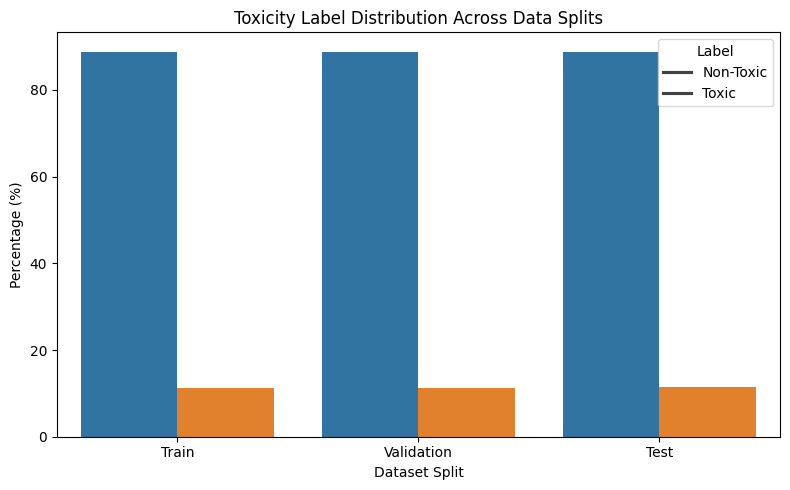

In [100]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=label_comparison,
    x="split",
    y="percentage",
    hue="label"
)

plt.title("Toxicity Label Distribution Across Data Splits")
plt.xlabel("Dataset Split")
plt.ylabel("Percentage (%)")

plt.legend(
    title="Label",
    labels=["Non-Toxic", "Toxic"]
)

plt.tight_layout()
plt.show()

### Compare identity prevalence

In [101]:
def identity_summary(df, split_name, identity_columns):
    results = []

    for identity in identity_columns:

        mask = df[identity] >= 0.5

        results.append({
            "split": split_name,
            "identity": identity,
            "count": int(mask.sum()),
            "percentage": mask.mean() * 100
        })

    return pd.DataFrame(results)

In [102]:
print("TRAIN COLUMNS")
for col in train_df.columns:
    print(col)

print("\nVALIDATION COLUMNS")
for col in val_df.columns:
    print(col)

print("\nTEST COLUMNS")
for col in test_df.columns:
    print(col)

print("Train and validation same columns:",
      set(train_df.columns) == set(val_df.columns))

print("Train and test same columns:",
      set(train_df.columns) == set(test_df.columns))
    ### should be True, True

TRAIN COLUMNS
text
toxicity
label
text_length

VALIDATION COLUMNS
text
toxicity
label
text_length

TEST COLUMNS
text
toxicity
label
text_length
Train and validation same columns: True
Train and test same columns: True


In [103]:
identity_columns = []
for col in identity_columns:
    print(f"\n--- {col} ---")
    print(train_df[col].value_counts(dropna=False).sort_index())

    print(f"\n--- {col} (Validation) ---")
    print(val_df[col].value_counts(dropna=False).sort_index())

    print(f"\n--- {col} (Test) ---")
    print(test_df[col].value_counts(dropna=False).sort_index())


identity_comparison = pd.concat([
    identity_summary(
        train_df,
        "Train",
        identity_columns
    ),

    identity_summary(
        val_df,
        "Validation",
        identity_columns
    ),

    identity_summary(
        test_df,
        "Test",
        identity_columns
    )
], ignore_index=True)

identity_comparison.head(20)

""


In [104]:
print(identity_comparison.columns.tolist())
display(identity_comparison.head())

[]


""


In [105]:
identity_columns = [
    "male", "female", "LGBTQ", "christian", "muslim",
    "other_religions", "black", "white", "identity_any"
]

splits = {
    "train": ds["train"],
    "validation": ds["validation"],
    "test": ds["test"]
}

identity_comparison_rows = []

for split_name, split_data in splits.items():
    split_df = split_data.to_pandas()
    total_comments = len(split_df)

    for col in identity_columns:
        if col not in split_df.columns:
            continue

        count = (split_df[col] > 0).sum()

        identity_comparison_rows.append({
            "identity": col,
            "split": split_name,
            "count": int(count),
            "percentage": count / total_comments * 100
        })

identity_comparison = pd.DataFrame(identity_comparison_rows)

display(identity_comparison.head())

,identity,split,count,percentage
0,male,train,29681,11.095037
1,female,train,36082,13.487791
2,LGBTQ,train,8369,3.128411
3,christian,train,26645,9.960152
4,muslim,train,13836,5.172027


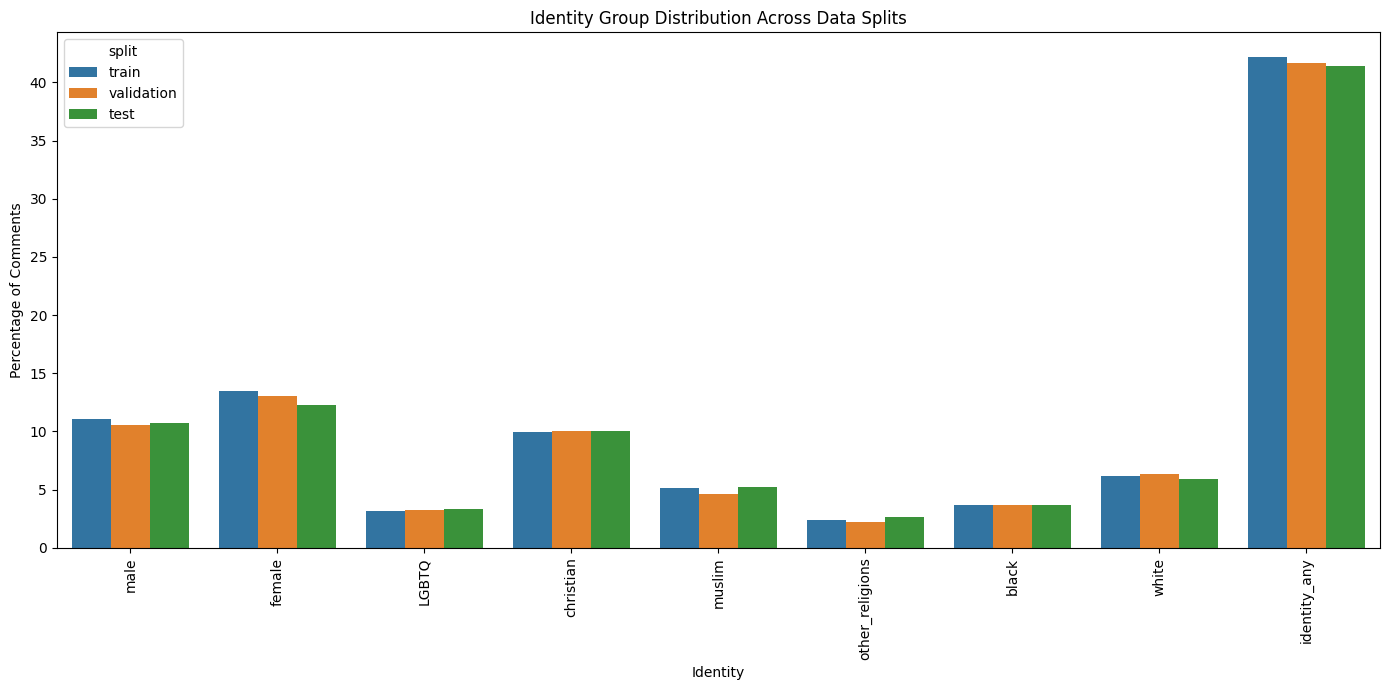

In [106]:
plt.figure(figsize=(14, 7))

sns.barplot(
    data=identity_comparison,
    x="identity",
    y="percentage",
    hue="split"
)

plt.xticks(rotation=90)
plt.title("Identity Group Distribution Across Data Splits")
plt.xlabel("Identity")
plt.ylabel("Percentage of Comments")
plt.tight_layout()
plt.show()

### Analyze toxicity

In [107]:
def group_toxicity_summary(df, split_name, identity_columns):
    results = []

    for identity in identity_columns:

        mask = df[identity] >= 0.5
        subset = df.loc[mask]

        if len(subset) == 0:
            continue

        results.append({
            "split": split_name,
            "identity": identity,
            "n": len(subset),
            "toxic_n": int(subset["label"].sum()),
            "toxicity_rate": subset["label"].mean()
        })

    return pd.DataFrame(results)

In [108]:
import pandas as pd

identity_columns = [
    "male", "female", "LGBTQ", "christian", "muslim",
    "other_religions", "black", "white", "identity_any"
]

def group_toxicity_summary(split_data, split_name, identity_columns):
    # Use the complete dataset split
    if hasattr(split_data, "to_pandas"):
        split_df = split_data.to_pandas()
    else:
        split_df = split_data.copy()

    rows = []

    # Binary toxicity label, consistent across all splits
    labels = (split_df["toxicity"] >= 0.5).astype(int)

    for col in identity_columns:
        if col not in split_df.columns:
            continue

        subset = split_df[col] > 0
        count = int(subset.sum())

        if count == 0:
            continue

        rows.append({
            "group": col,
            "split": split_name,
            "count": count,
            "toxicity_rate": labels.loc[subset].mean()
        })

    return pd.DataFrame(rows)


group_toxicity = pd.concat([
    group_toxicity_summary(ds["train"], "Train", identity_columns),
    group_toxicity_summary(ds["validation"], "Validation", identity_columns),
    group_toxicity_summary(ds["test"], "Test", identity_columns)
], ignore_index=True)

group_toxicity = group_toxicity.sort_values(
    ["split", "toxicity_rate"],
    ascending=[True, False]
).reset_index(drop=True)

display(group_toxicity)

,group,split,count,toxicity_rate
0,black,Test,4834,0.313819
1,white,Test,7852,0.281202
2,LGBTQ,Test,4398,0.273988
3,muslim,Test,6899,0.234237
4,identity_any,Test,54942,0.165192
5,male,Test,14206,0.153949
6,other_religions,Test,3464,0.149249
7,female,Test,16335,0.137863
8,christian,Test,13304,0.094257
9,black,Train,9824,0.313721


In [109]:
group_toxicity_display = group_toxicity.copy()

group_toxicity_display["toxicity_rate"] = (
    group_toxicity_display["toxicity_rate"] * 100
).round(2)

display(group_toxicity_display)

,group,split,count,toxicity_rate
0,black,Test,4834,31.38
1,white,Test,7852,28.12
2,LGBTQ,Test,4398,27.40
3,muslim,Test,6899,23.42
4,identity_any,Test,54942,16.52
5,male,Test,14206,15.39
6,other_religions,Test,3464,14.92
7,female,Test,16335,13.79
8,christian,Test,13304,9.43
9,black,Train,9824,31.37


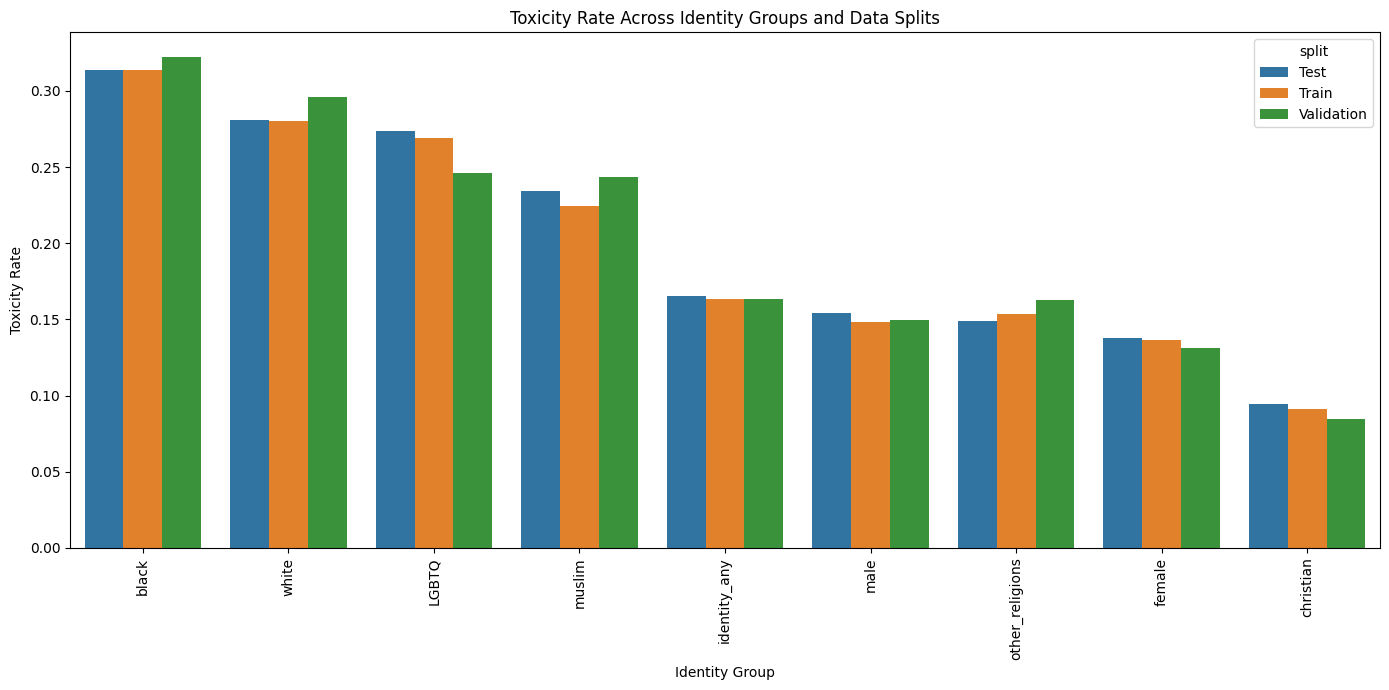

In [110]:
plt.figure(figsize=(14, 7))

sns.barplot(
    data=group_toxicity,
    x="group",
    y="toxicity_rate",
    hue="split"
)

plt.xticks(rotation=90)
plt.title("Toxicity Rate Across Identity Groups and Data Splits")
plt.xlabel("Identity Group")
plt.ylabel("Toxicity Rate")
plt.tight_layout()
plt.show()

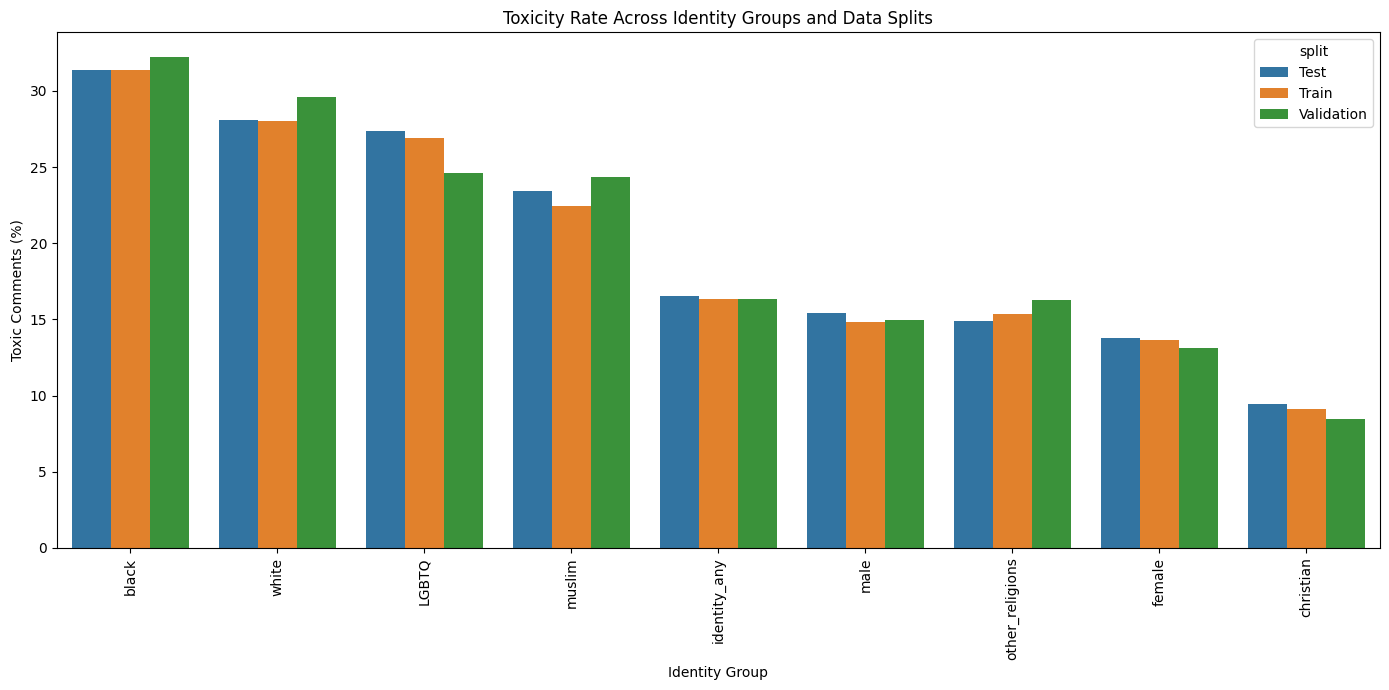

In [111]:
group_toxicity_plot = group_toxicity.copy()
group_toxicity_plot["toxicity_rate"] *= 100

plt.figure(figsize=(14, 7))

sns.barplot(
    data=group_toxicity_plot,
    x="group",
    y="toxicity_rate",
    hue="split"
)

plt.xticks(rotation=90)
plt.title("Toxicity Rate Across Identity Groups and Data Splits")
plt.xlabel("Identity Group")
plt.ylabel("Toxic Comments (%)")
plt.tight_layout()
plt.show()

In [112]:
from pathlib import Path

report_dir = Path("reports")
report_dir.mkdir(exist_ok=True)

identity_comparison.to_csv(
    report_dir / "identity_distribution.csv",
    index=False
)

group_toxicity.to_csv(
    report_dir / "identity_toxicity_rates.csv",
    index=False
)

print("Group analysis saved.")

Group analysis saved.
